<a href="https://colab.research.google.com/github/Milu2662/BI-PYMES-ML/blob/main/notebook/01_data_exploration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# BI-PYMES-ML — configuración

In [2]:
!git clone https://github.com/Milu2662/BI-PYMES-ML.git /content/BI-PYMES-ML

Cloning into '/content/BI-PYMES-ML'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (22/22), done.
remote: Total 34 (delta 6), reused 31 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 15.41 KiB | 3.85 MiB/s, done.
Resolving deltas: 100% (6/6), done.


In [3]:
from pathlib import Path
import sys
candidates=[Path("/content/BI-PYMES-ML"),Path("/content/BI-PYMES-ML"),Path.cwd()]
PROJECT_DIR=next((p for p in candidates if (p/"src").exists()),Path.cwd())
if not (PROJECT_DIR/"src").exists():
    raise FileNotFoundError("No se encontró src/. Ajusta PROJECT_DIR a la raíz del repositorio.")
sys.path.insert(0,str(PROJECT_DIR))
for d in ["data/raw","data/processed","data/experimental","results/figures","results/metrics"]:
    (PROJECT_DIR/d).mkdir(parents=True,exist_ok=True)
print("Proyecto:",PROJECT_DIR)

Proyecto: /content/BI-PYMES-ML


## 1. Descarga y exploración
Dataset: Online Retail II, UCI Machine Learning Repository.

In [4]:
import pandas as pd
from src.preprocessing import download_online_retail_ii,load_retail_excel,quality_profile
xlsx=download_online_retail_ii(PROJECT_DIR/"data/raw")
df=load_retail_excel(xlsx)
print("Archivo:",xlsx,"\nDimensiones:",df.shape)
display(df.head())
display(df.dtypes)

Archivo: /content/BI-PYMES-ML/data/raw/online_retail_II.xlsx 
Dimensiones: (1067371, 10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SourceSheet,Revenue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom,Year 2009-2010,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom,Year 2009-2010,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom,Year 2009-2010,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom,Year 2009-2010,30.0


,0
InvoiceNo,string[python]
StockCode,object
Description,object
Quantity,int64
InvoiceDate,datetime64[ns]
UnitPrice,float64
CustomerID,float64
Country,object
SourceSheet,object
Revenue,float64


In [5]:
profile,checks=quality_profile(df)
display(profile)
print(checks)
profile.to_csv(PROJECT_DIR/"results/metrics/initial_data_profile.csv")
pd.Series(checks).to_json(PROJECT_DIR/"results/metrics/initial_quality_checks.json",indent=2)
df.to_pickle(PROJECT_DIR/"data/processed/retail_lines.pkl")

,dtype,missing_count,missing_pct,unique_count
InvoiceNo,string,0,0.000,53628
StockCode,object,0,0.000,5305
Description,object,4382,0.411,5698
Quantity,int64,0,0.000,1057
InvoiceDate,datetime64[ns],0,0.000,47635
UnitPrice,float64,0,0.000,2807
CustomerID,float64,243007,22.767,5942
Country,object,0,0.000,43
SourceSheet,object,0,0.000,2
Revenue,float64,0,0.000,9113


{'rows': 1067371, 'columns': 10, 'exact_duplicates': 12133, 'quantity_negative': 22950, 'quantity_zero': 0, 'price_negative': 5, 'invalid_dates': 0, 'cancellation_invoices': 19494}


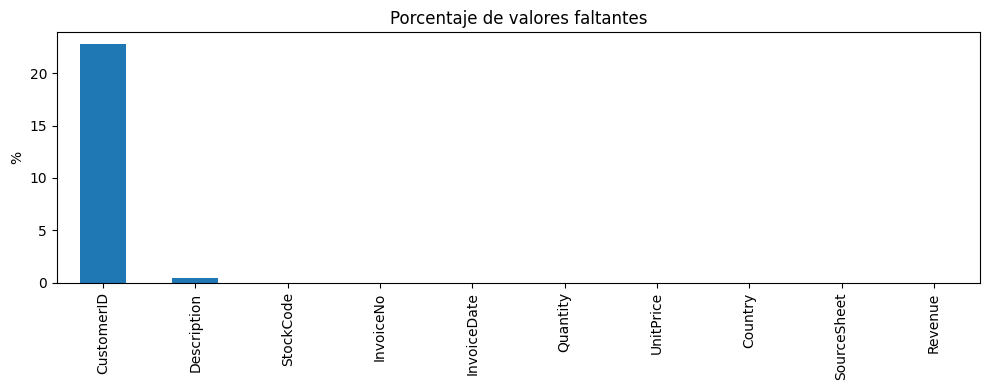

In [6]:
import matplotlib.pyplot as plt
missing=(df.isna().mean()*100).sort_values(ascending=False)
ax=missing.plot(kind="bar",figsize=(10,4),title="Porcentaje de valores faltantes")
ax.set_ylabel("%"); plt.tight_layout()
plt.savefig(PROJECT_DIR/"results/figures/missing_values.png",dpi=160)
plt.show()